In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
from pathlib import Path
import pandas as pd

file_path = Path("../data/processed/superstore_dataset_cleaned.csv")

if not file_path.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {file_path.resolve()}\n"
        "Check the CSV filename and notebook location."
    )

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 9994
Columns: 21


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,postal_code,region,product_id,category,sub-category,product_name,sales,quantity,discount,profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
# Standardize column names
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   row_id         9994 non-null   int64  
 1   order_id       9994 non-null   str    
 2   order_date     9994 non-null   str    
 3   ship_date      9994 non-null   str    
 4   ship_mode      9994 non-null   str    
 5   customer_id    9994 non-null   str    
 6   customer_name  9994 non-null   str    
 7   segment        9994 non-null   str    
 8   country        9994 non-null   str    
 9   city           9994 non-null   str    
 10  state          9994 non-null   str    
 11  postal_code    9994 non-null   

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
row_id,9994.0,NaN,NaN,NaN,4997.5,2885.163629,1.0,2499.25,4997.5,7495.75,9994.0
order_id,9994,5009,CA-2017-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,9994,1237,9/5/2016,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ship_date,9994,1334,12/16/2015,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ship_mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print("Missing values in each column:")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

print("Duplicate rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nUnique values in important columns:")
for col in ["category", "sub_category", "region", "segment", "ship_mode"]:
    if col in df.columns:
        print(f"{col}: {df[col].nunique()} unique values")

Missing values in each column:


,Missing Values
row_id,0
order_id,0
order_date,0
ship_date,0
ship_mode,0
customer_id,0
customer_name,0
segment,0
country,0
city,0


Duplicate rows: 0

Data types:


,Data Type
row_id,int64
order_id,str
order_date,str
ship_date,str
ship_mode,str
customer_id,str
customer_name,str
segment,str
country,str
city,str



Unique values in important columns:
category: 3 unique values
sub_category: 17 unique values
region: 4 unique values
segment: 3 unique values
ship_mode: 4 unique values


In [5]:
# Convert date columns
for col in ["order_date", "ship_date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# Convert numeric columns
numeric_cols = [
    "sales", "profit", "quantity",
    "discount", "postal_code"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Data preparation completed.")
display(df.head())

Data preparation completed.


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [6]:
required = ["sales", "profit"]

missing = [col for col in required if col not in df.columns]

if missing:
    print("Cannot calculate all KPIs. Missing columns:", missing)
else:
    total_sales = df["sales"].sum()
    total_profit = df["profit"].sum()
    profit_margin = (
        total_profit / total_sales * 100
        if total_sales != 0 else np.nan
    )

    print(f"Total Sales: {total_sales:,.2f}")
    print(f"Total Profit: {total_profit:,.2f}")
    print(f"Overall Profit Margin: {profit_margin:.2f}%")

    if "order_id" in df.columns:
        print("Unique Orders:", df["order_id"].nunique())

    if "customer_id" in df.columns:
        print("Unique Customers:", df["customer_id"].nunique())

    if "quantity" in df.columns:
        print("Total Quantity Sold:", df["quantity"].sum())

Total Sales: 2,297,200.86
Total Profit: 286,397.02
Overall Profit Margin: 12.47%
Unique Orders: 5009
Unique Customers: 793
Total Quantity Sold: 37873


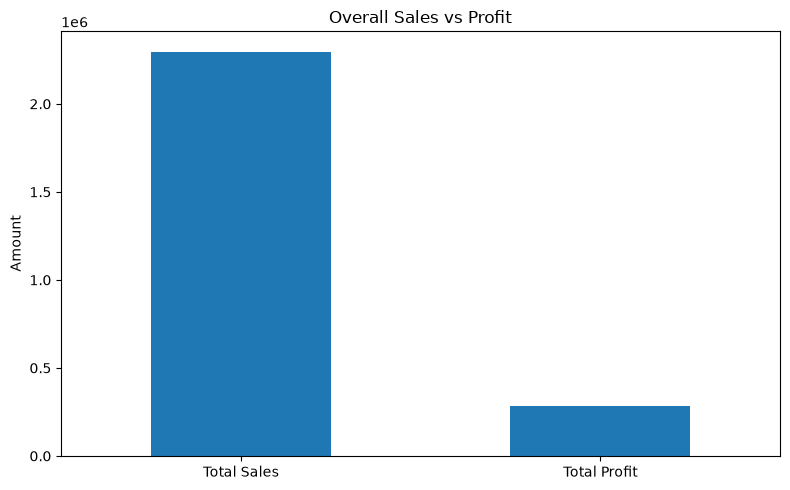

In [8]:
if {"sales", "profit"}.issubset(df.columns):
    totals = pd.Series({
        "Total Sales": df["sales"].sum(),
        "Total Profit": df["profit"].sum()
    })

    totals.plot(kind="bar", figsize=(8, 5))
    import matplotlib.pyplot as plt
    plt.title("Overall Sales vs Profit")
    plt.ylabel("Amount")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

,Total_Sales,Total_Profit,Profit_Margin_%
category,,,
Technology,836154.03,145454.95,17.40
Furniture,741999.80,18451.27,2.49
Office Supplies,719047.03,122490.80,17.04


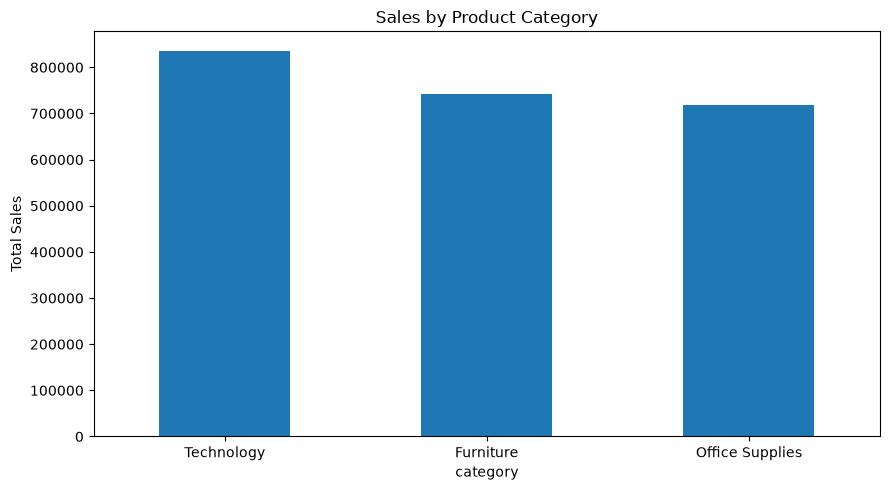

In [10]:
if {"category", "sales", "profit"}.issubset(df.columns):
    category_analysis = (
        df.groupby("category")
        .agg(
            Total_Sales=("sales", "sum"),
            Total_Profit=("profit", "sum")
        )
        .sort_values("Total_Sales", ascending=False)
    )

    category_analysis["Profit_Margin_%"] = (
        category_analysis["Total_Profit"]
        / category_analysis["Total_Sales"].where(
            category_analysis["Total_Sales"].ne(0)
        )
        * 100
    )

    display(category_analysis.round(2))

    category_analysis["Total_Sales"].plot(
        kind="bar", figsize=(9, 5)
    )
    plt.title("Sales by Product Category")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("Required columns: category, sales, profit")

,Total_Sales,Total_Profit
sub_category,,
Tables,206965.53,-17725.48
Bookcases,114880.00,-3472.56
Supplies,46673.54,-1189.10
Fasteners,3024.28,949.52
Machines,189238.63,3384.76
Labels,12486.31,5546.25
Art,27118.79,6527.79
Envelopes,16476.40,6964.18
Furnishings,91705.16,13059.14


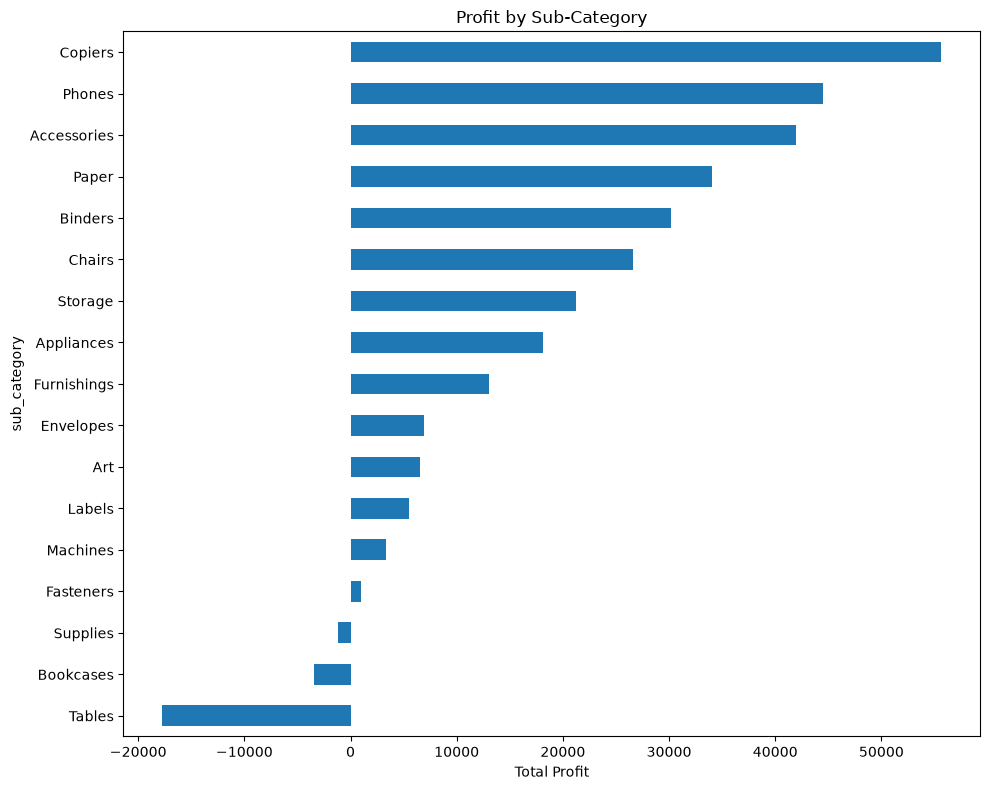

In [11]:
if {"sub_category", "sales", "profit"}.issubset(df.columns):
    subcategory_analysis = (
        df.groupby("sub_category")
        .agg(
            Total_Sales=("sales", "sum"),
            Total_Profit=("profit", "sum")
        )
        .sort_values("Total_Profit", ascending=True)
    )

    display(subcategory_analysis.round(2))

    subcategory_analysis["Total_Profit"].plot(
        kind="barh", figsize=(10, 8)
    )
    plt.title("Profit by Sub-Category")
    plt.xlabel("Total Profit")
    plt.tight_layout()
    plt.show()

,Total_Sales,Total_Profit,Profit_Margin_%
region,,,
West,725457.82,108418.45,14.94
East,678781.24,91522.78,13.48
South,391721.90,46749.43,11.93
Central,501239.89,39706.36,7.92


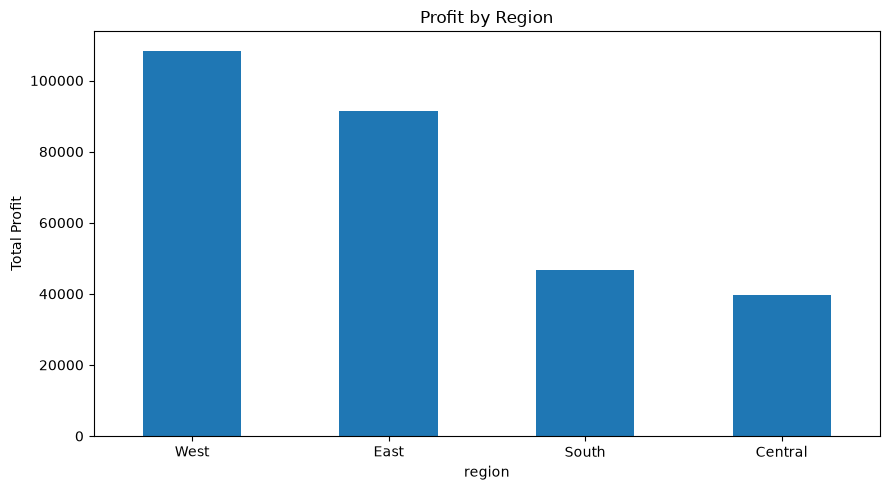

In [13]:
if {"region", "sales", "profit"}.issubset(df.columns):
    region_analysis = (
        df.groupby("region")
        .agg(
            Total_Sales=("sales", "sum"),
            Total_Profit=("profit", "sum")
        )
        .sort_values("Total_Profit", ascending=False)
    )

    region_analysis["Profit_Margin_%"] = (
        region_analysis["Total_Profit"]
        / region_analysis["Total_Sales"].where(
            region_analysis["Total_Sales"].ne(0)
        )
        * 100
    )

    display(region_analysis.round(2))

    region_analysis["Total_Profit"].plot(
        kind="bar", figsize=(9, 5)
    )
    plt.title("Profit by Region")
    plt.ylabel("Total Profit")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [14]:
if {"state", "sales", "profit"}.issubset(df.columns):
    state_analysis = (
        df.groupby("state")
        .agg(
            Total_Sales=("sales", "sum"),
            Total_Profit=("profit", "sum")
        )
        .sort_values("Total_Profit")
    )

    print("10 Lowest-Profit States:")
    display(state_analysis.head(10).round(2))

    print("10 Highest-Profit States:")
    display(state_analysis.tail(10).sort_values(
        "Total_Profit", ascending=False
    ).round(2))

10 Lowest-Profit States:


,Total_Sales,Total_Profit
state,,
Texas,170188.05,-25729.36
Ohio,78258.14,-16971.38
Pennsylvania,116511.91,-15559.96
Illinois,80166.10,-12607.89
North Carolina,55603.16,-7490.91
Colorado,32108.12,-6527.86
Tennessee,30661.87,-5341.69
Arizona,35282.00,-3427.92
Florida,89473.71,-3399.30


10 Highest-Profit States:


,Total_Sales,Total_Profit
state,,
California,457687.63,76381.39
New York,310876.27,74038.55
Washington,138641.27,33402.65
Michigan,76269.61,24463.19
Virginia,70636.72,18597.95
Indiana,53555.36,18382.94
Georgia,49095.84,16250.04
Kentucky,36591.75,11199.70
Minnesota,29863.15,10823.19


,Total_Sales,Total_Profit
segment,,
Consumer,1161401.34,134119.21
Corporate,706146.37,91979.13
Home Office,429653.15,60298.68


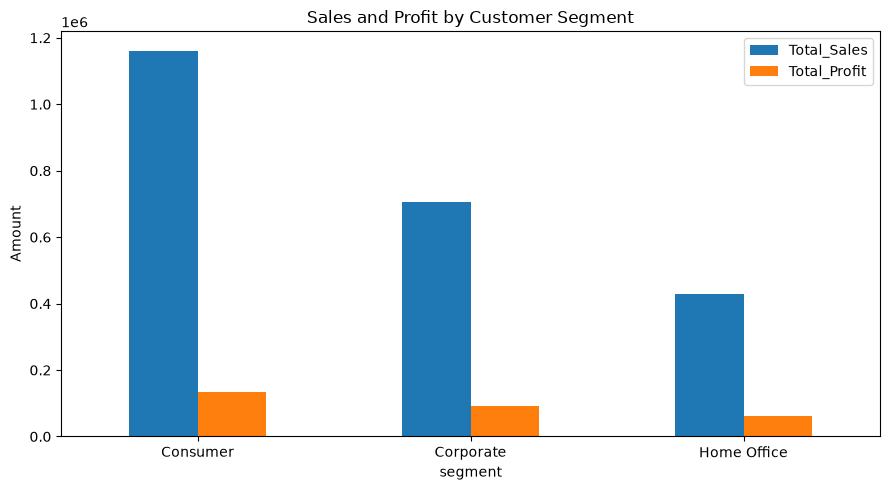

In [15]:
if {"segment", "sales", "profit"}.issubset(df.columns):
    segment_analysis = (
        df.groupby("segment")
        .agg(
            Total_Sales=("sales", "sum"),
            Total_Profit=("profit", "sum")
        )
        .sort_values("Total_Sales", ascending=False)
    )

    display(segment_analysis.round(2))

    segment_analysis[["Total_Sales", "Total_Profit"]].plot(
        kind="bar", figsize=(9, 5)
    )
    plt.title("Sales and Profit by Customer Segment")
    plt.ylabel("Amount")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

,Total_Sales,Total_Profit,Average_Profit,Number_of_Records
discount,,,,
0.00,1087908.47,320987.60,66.90,4798
0.10,54369.35,9029.18,96.06,94
0.15,27558.52,1418.99,27.29,52
0.20,764594.37,90337.31,24.70,3657
0.30,103226.66,-10369.28,-45.68,227
0.32,14493.46,-2391.14,-88.56,27
0.40,116417.78,-23057.05,-111.93,206
0.45,5484.97,-2493.11,-226.65,11
0.50,58918.54,-20506.43,-310.70,66


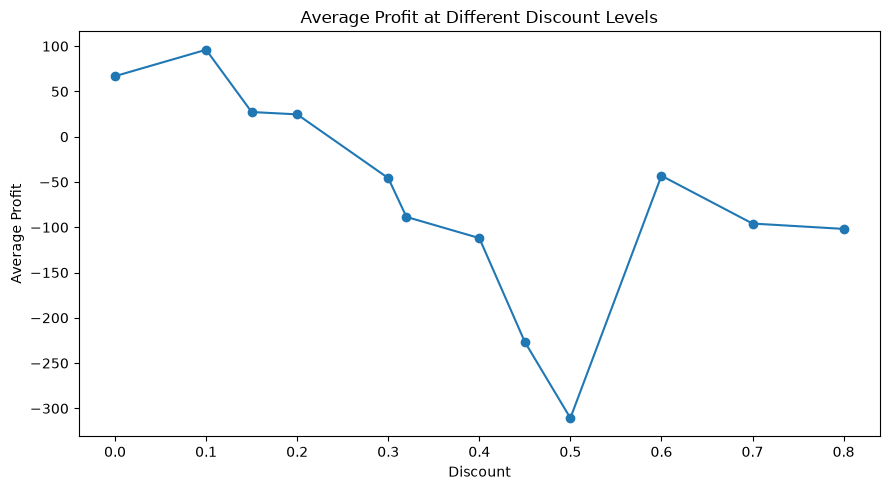

In [16]:
if {"discount", "sales", "profit"}.issubset(df.columns):
    discount_analysis = (
        df.groupby("discount")
        .agg(
            Total_Sales=("sales", "sum"),
            Total_Profit=("profit", "sum"),
            Average_Profit=("profit", "mean"),
            Number_of_Records=("profit", "size")
        )
        .sort_index()
    )

    display(discount_analysis.round(2))

    discount_analysis["Average_Profit"].plot(
        marker="o", figsize=(9, 5)
    )
    plt.title("Average Profit at Different Discount Levels")
    plt.xlabel("Discount")
    plt.ylabel("Average Profit")
    plt.tight_layout()
    plt.show()
else:
    print("Required columns: discount, sales, profit")

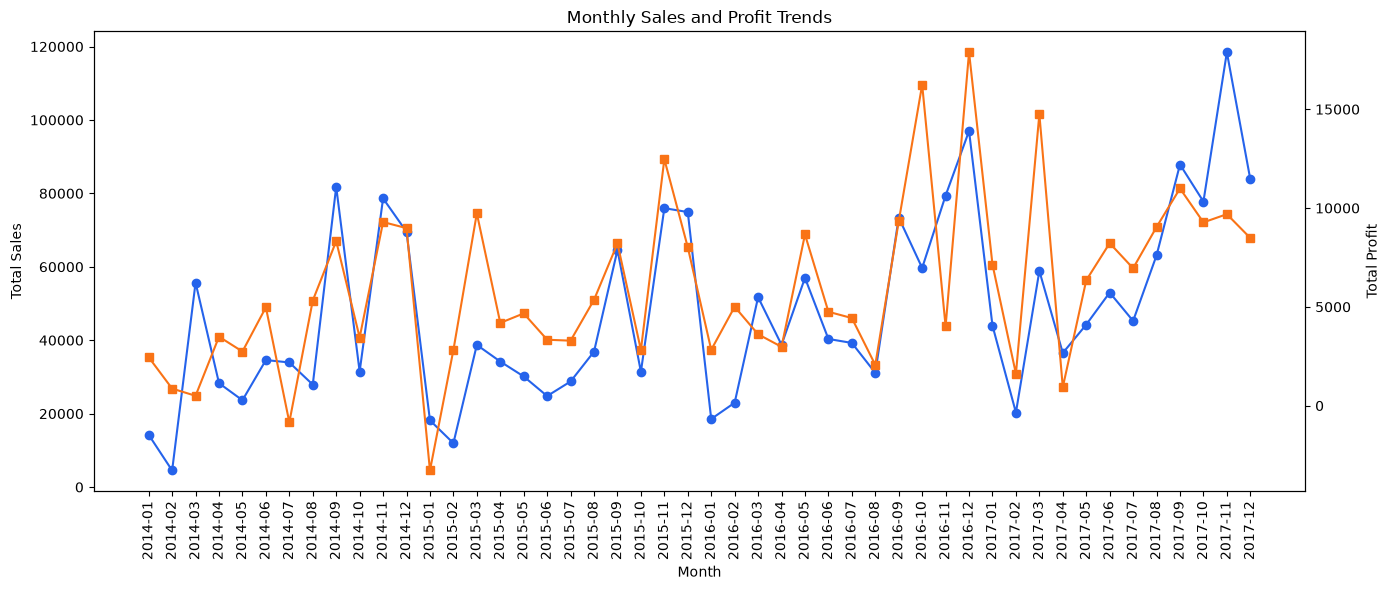

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load your cleaned dataset
df = pd.read_csv("../data/processed/superstore_dataset_cleaned.csv")

# Clean column names
df.columns = df.columns.str.strip().str.lower()

# Convert order date to datetime
# Support either "order_date" or "order date"
date_col = "order_date" if "order_date" in df.columns else "order date"

if date_col not in df.columns:
    raise KeyError(f"Date column not found. Available columns: {df.columns.tolist()}")

df["order date"] = pd.to_datetime(
    df[date_col],
    errors="coerce"
)

# Create monthly sales and profit summary
df["year_month"] = df["order date"].dt.to_period("M")

monthly_data = df.groupby("year_month").agg({
    "sales": "sum",
    "profit": "sum"
}).reset_index()

monthly_data["year_month"] = (
    monthly_data["year_month"].astype(str)
)

# Plot monthly sales and profit
fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(
    monthly_data["year_month"],
    monthly_data["sales"],
    color="#2563EB",
    marker="o",
    label="Sales"
)
ax1.set_xlabel("Month")
ax1.set_ylabel("Total Sales")
ax1.tick_params(axis="x", rotation=90)

ax2 = ax1.twinx()
ax2.plot(
    monthly_data["year_month"],
    monthly_data["profit"],
    color="#F97316",
    marker="s",
    label="Profit"
)
ax2.set_ylabel("Total Profit")

plt.title("Monthly Sales and Profit Trends")
fig.tight_layout()
plt.show()

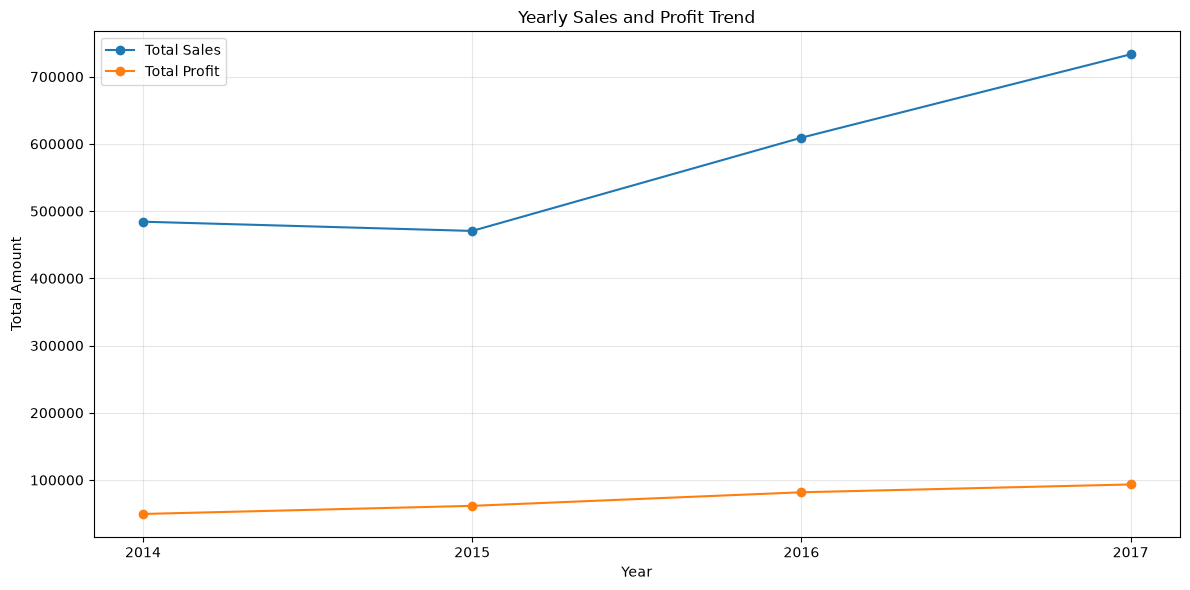

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert Order Date to datetime
df["order_date"] = pd.to_datetime(df["order_date"])

# Extract year
df["year"] = df["order_date"].dt.year

# Calculate yearly sales and profit
yearly_data = df.groupby("year")[["sales", "profit"]].sum()

# Plot yearly trends
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_data.index,
    yearly_data["sales"],
    marker="o",
    label="Total Sales"
)

plt.plot(
    yearly_data.index,
    yearly_data["profit"],
    marker="o",
    label="Total Profit"
)

plt.title("Yearly Sales and Profit Trend")
plt.xlabel("Year")
plt.ylabel("Total Amount")
plt.xticks(yearly_data.index)  # Show every year
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
if {"order_date", "sales", "profit"}.issubset(df.columns):
    dated_df = df.dropna(subset=["order_date"]).copy()

    dated_df["quarter"] = (
        dated_df["order_date"].dt.to_period("Q").astype(str)
    )

    quarterly_analysis = (
        dated_df.groupby("quarter")
        .agg(
            Total_Sales=("sales", "sum"),
            Total_Profit=("profit", "sum")
        )
        .sort_index()
    )

    display(quarterly_analysis)

,Total_Sales,Total_Profit
quarter,,
2014Q1,74447.7960,3811.2290
2014Q2,86538.7596,11204.0692
2014Q3,143633.2123,12804.7218
2014Q4,179627.7302,21723.9541
2015Q1,68851.7386,9264.9416
2015Q2,89124.1870,12190.9224
2015Q3,130259.5752,16853.6194
2015Q4,182297.0082,23309.1203
2016Q1,93237.1810,11441.3708


,Total_Sales,Total_Profit,Order_Lines
ship_mode,,,
Standard Class,1358215.74,164088.79,5968
Second Class,459193.57,57446.64,1945
First Class,351428.42,48969.84,1538
Same Day,128363.12,15891.76,543


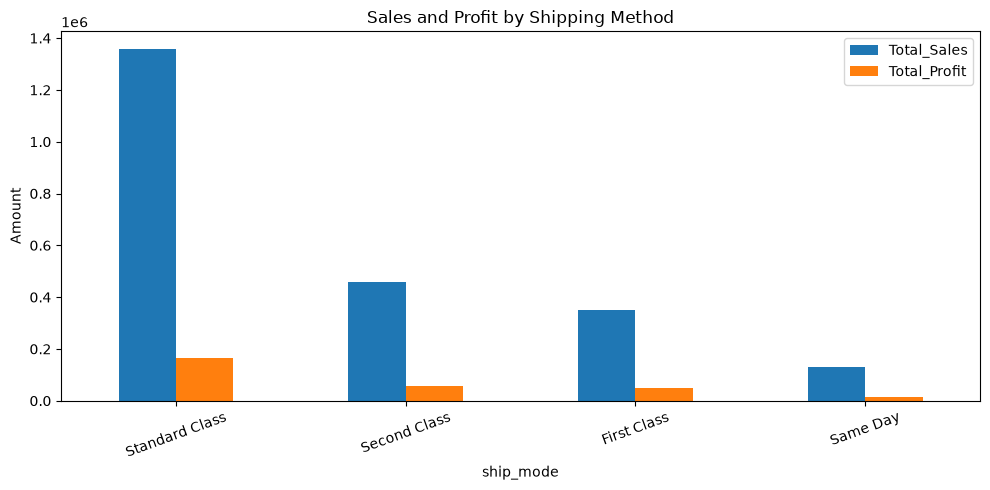

In [19]:
if {"ship_mode", "sales", "profit"}.issubset(df.columns):
    shipping_analysis = (
        df.groupby("ship_mode")
        .agg(
            Total_Sales=("sales", "sum"),
            Total_Profit=("profit", "sum"),
            Order_Lines=("sales", "size")
        )
        .sort_values("Total_Sales", ascending=False)
    )

    display(shipping_analysis.round(2))

    shipping_analysis[["Total_Sales", "Total_Profit"]].plot(
        kind="bar", figsize=(10, 5)
    )
    plt.title("Sales and Profit by Shipping Method")
    plt.ylabel("Amount")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

In [20]:
if {"product_name", "sales", "profit"}.issubset(df.columns):
    product_analysis = (
        df.groupby("product_name")
        .agg(
            Total_Sales=("sales", "sum"),
            Total_Profit=("profit", "sum")
        )
    )

    print("Top 10 Products by Sales:")
    display(
        product_analysis.sort_values(
            "Total_Sales", ascending=False
        ).head(10).round(2)
    )

    print("10 Products with Lowest Total Profit:")
    display(
        product_analysis.sort_values(
            "Total_Profit", ascending=True
        ).head(10).round(2)
    )

Top 10 Products by Sales:


,Total_Sales,Total_Profit
product_name,,
Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.38,7753.04
Cisco TelePresence System EX90 Videoconferencing Unit,22638.48,-1811.08
HON 5400 Series Task Chairs for Big and Tall,21870.58,0.00
GBC DocuBind TL300 Electric Binding System,19823.48,2233.51
GBC Ibimaster 500 Manual ProClick Binding System,19024.50,760.98
Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.90,4094.98
GBC DocuBind P400 Electric Binding System,17965.07,-1878.17


10 Products with Lowest Total Profit:


,Total_Sales,Total_Profit
product_name,,
Cubify CubeX 3D Printer Double Head Print,11099.96,-8879.97
Lexmark MX611dhe Monochrome Laser Printer,16829.90,-4589.97
Cubify CubeX 3D Printer Triple Head Print,7999.98,-3839.99
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.64,-2876.12
Bush Advantage Collection Racetrack Conference Table,9544.72,-1934.40
GBC DocuBind P400 Electric Binding System,17965.07,-1878.17
Cisco TelePresence System EX90 Videoconferencing Unit,22638.48,-1811.08
Martin Yale Chadless Opener Electric Letter Opener,16656.20,-1299.18
Balt Solid Wood Round Tables,6518.75,-1201.06


In [21]:
if {"sales", "profit"}.issubset(df.columns):
    print("=" * 45)
    print("SUPERSTORE BUSINESS SUMMARY")
    print("=" * 45)

    print(f"Total Sales: {df['sales'].sum():,.2f}")
    print(f"Total Profit: {df['profit'].sum():,.2f}")

    sales_total = df["sales"].sum()
    margin = (
        df["profit"].sum() / sales_total * 100
        if sales_total != 0 else np.nan
    )
    print(f"Profit Margin: {margin:.2f}%")

    if "category" in df.columns:
        category_profit = df.groupby("category")["profit"].sum()
        print("Most Profitable Category:", category_profit.idxmax())
        print("Least Profitable Category:", category_profit.idxmin())

    if "region" in df.columns:
        region_profit = df.groupby("region")["profit"].sum()
        print("Most Profitable Region:", region_profit.idxmax())
        print("Lowest-Profit Region:", region_profit.idxmin())

    if "segment" in df.columns:
        segment_sales = df.groupby("segment")["sales"].sum()
        print("Highest-Sales Customer Segment:", segment_sales.idxmax())

SUPERSTORE BUSINESS SUMMARY
Total Sales: 2,297,200.86
Total Profit: 286,397.02
Profit Margin: 12.47%
Most Profitable Category: Technology
Least Profitable Category: Furniture
Most Profitable Region: West
Lowest-Profit Region: Central
Highest-Sales Customer Segment: Consumer


In [25]:
# Display EDA results directly in the notebook

print("CATEGORY ANALYSIS")
if "category_analysis" in globals():
    display(category_analysis)

print("\nREGION ANALYSIS")
if "region_analysis" in globals():
    display(region_analysis)

print("\nCUSTOMER SEGMENT ANALYSIS")
if "segment_analysis" in globals():
    display(segment_analysis)

CATEGORY ANALYSIS


,Total_Sales,Total_Profit,Profit_Margin_%
category,,,
Technology,836154.0330,145454.9481,17.395712
Furniture,741999.7953,18451.2728,2.486695
Office Supplies,719047.0320,122490.8008,17.035158



REGION ANALYSIS


,Total_Sales,Total_Profit,Profit_Margin_%
region,,,
West,725457.8245,108418.4489,14.944831
East,678781.2400,91522.7800,13.483399
South,391721.9050,46749.4303,11.934342
Central,501239.8908,39706.3625,7.921629



CUSTOMER SEGMENT ANALYSIS


,Total_Sales,Total_Profit
segment,,
Consumer,1.161401e+06,134119.2092
Corporate,7.061464e+05,91979.1340
Home Office,4.296531e+05,60298.6785


In [3]:
import pandas as pd
from pathlib import Path

# Load the cleaned dataset
file_path = Path("../data/processed/superstore_dataset_cleaned.csv")
df = pd.read_csv(file_path)

# Clean column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Check whether required columns exist
print("Available columns:", df.columns.tolist())

required = ["product_name", "profit"]

if not all(col in df.columns for col in required):
    print("Missing required columns:", [
        col for col in required if col not in df.columns
    ])
else:

    # 2. Profit by product sub-category
    if "sub-category" in df.columns:
        subcategory_col = "sub-category"
    elif "sub_category" in df.columns:
        subcategory_col = "sub_category"
    else:
        subcategory_col = None

    if subcategory_col:
        subcategory_profit = (
            df.groupby(subcategory_col, as_index=False)["profit"]
            .sum()
            .sort_values("profit", ascending=False)
        )
        print("\nProfit by Sub-Category:")
        print(subcategory_profit.to_string(index=False))

    # 3. Profit by category
    if "category" in df.columns:
        category_profit = (
            df.groupby("category", as_index=False)["profit"]
            .sum()
            .sort_values("profit", ascending=False)
        )
        print("\nProfit by Category:")
        print(category_profit.to_string(index=False))

    

Available columns: ['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub-category', 'product_name', 'sales', 'quantity', 'discount', 'profit']

Profit by Sub-Category:
sub-category      profit
     Copiers  55617.8249
      Phones  44515.7306
 Accessories  41936.6357
       Paper  34053.5693
     Binders  30221.7633
      Chairs  26590.1663
     Storage  21278.8264
  Appliances  18138.0054
 Furnishings  13059.1436
   Envelopes   6964.1767
         Art   6527.7870
      Labels   5546.2540
    Machines   3384.7569
   Fasteners    949.5182
    Supplies  -1189.0995
   Bookcases  -3472.5560
      Tables -17725.4811

Profit by Category:
       category      profit
     Technology 145454.9481
Office Supplies 122490.8008
      Furniture  18451.2728
